In [30]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [31]:
conn = sqlite3.connect("../data/checking-logs.sqlite")

In [32]:
dfWeekDays = pd.io.sql.read_sql(
    """
    ---sql
    WITH CTE AS (
    SELECT uid,
        CASE CAST(strftime('%w', timestamp) AS INT)
            WHEN 0 THEN 'Sun'
            WHEN 1 THEN 'Mon'
            WHEN 2 THEN 'Tue'
            WHEN 3 THEN 'Wed'
            WHEN 4 THEN 'Thu'
            WHEN 5 THEN 'Fri'
            WHEN 6 THEN 'Sat'
        END AS day_name
        FROM checker
        WHERE uid NOT LIKE 'admin_%')

        SELECT uid, day_name, COUNT(*) AS commits
        FROM CTE GROUP BY uid, day_name
    """,
    conn,
)

print(dfWeekDays.head(3))

      uid day_name  commits
0  user_0      Mon        3
1  user_1      Sat        1
2  user_1      Sun       43


In [33]:
pvt_days = dfWeekDays.pivot(index="day_name", columns="uid", values="commits").fillna(0)
pvt_days

uid,user_0,user_1,user_10,user_11,user_12,user_13,user_14,user_15,user_16,user_17,...,user_27,user_28,user_29,user_3,user_30,user_31,user_4,user_6,user_7,user_8
day_name,,,,,,,,,,,,,,,,,,,,,
Fri,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,7.0,1.0,59.0,3.0,35.0,61.0,0.0,0.0,0.0
Mon,3.0,0.0,0.0,0.0,2.0,3.0,50.0,0.0,10.0,8.0,...,0.0,0.0,9.0,46.0,2.0,5.0,35.0,1.0,0.0,0.0
Sat,0.0,1.0,4.0,0.0,7.0,28.0,79.0,4.0,0.0,32.0,...,0.0,12.0,2.0,3.0,22.0,90.0,0.0,2.0,0.0,46.0
Sun,0.0,43.0,2.0,8.0,76.0,23.0,26.0,20.0,31.0,0.0,...,27.0,32.0,26.0,8.0,21.0,7.0,45.0,9.0,0.0,26.0
Thu,0.0,39.0,77.0,0.0,7.0,4.0,17.0,5.0,14.0,17.0,...,15.0,12.0,25.0,7.0,20.0,7.0,108.0,2.0,0.0,15.0
Tue,0.0,0.0,16.0,0.0,1.0,57.0,87.0,0.0,5.0,4.0,...,0.0,7.0,26.0,11.0,3.0,0.0,86.0,0.0,5.0,0.0
Wed,0.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,44.0,32.0,0.0,1.0,0.0,33.0,4.0,3.0,0.0


In [34]:
daysOrder = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
daysOrder

['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

In [35]:
userOrder = pvt_days.sum().sort_values(ascending=False).index
userOrder

Index(['user_4', 'user_14', 'user_2', 'user_25', 'user_19', 'user_26',
       'user_20', 'user_31', 'user_10', 'user_3', 'user_29', 'user_13',
       'user_28', 'user_24', 'user_12', 'user_8', 'user_1', 'user_21',
       'user_30', 'user_18', 'user_17', 'user_16', 'user_27', 'user_15',
       'user_6', 'user_11', 'user_7', 'user_22', 'user_23', 'user_0'],
      dtype='str', name='uid')

In [36]:
pvt_days = pvt_days.reindex(index=daysOrder, columns=userOrder)
pvt_days

uid,user_4,user_14,user_2,user_25,user_19,user_26,user_20,user_31,user_10,user_3,...,user_17,user_16,user_27,user_15,user_6,user_11,user_7,user_22,user_23,user_0
day_name,,,,,,,,,,,,,,,,,,,,,
Mon,35.0,50.0,24.0,14.0,7.0,0.0,23.0,5.0,0.0,46.0,...,8.0,10.0,0.0,0.0,1.0,0.0,0.0,2.0,0.0,3.0
Tue,86.0,87.0,131.0,44.0,9.0,1.0,0.0,0.0,16.0,11.0,...,4.0,5.0,0.0,0.0,0.0,0.0,5.0,3.0,0.0,0.0
Wed,33.0,0.0,32.0,15.0,0.0,34.0,8.0,0.0,37.0,0.0,...,1.0,0.0,0.0,0.0,4.0,0.0,3.0,0.0,0.0,0.0
Thu,108.0,17.0,4.0,40.0,78.0,51.0,96.0,7.0,77.0,7.0,...,17.0,14.0,15.0,5.0,2.0,0.0,0.0,2.0,6.0,0.0
Fri,61.0,0.0,0.0,10.0,10.0,2.0,7.0,35.0,1.0,59.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Sat,0.0,79.0,31.0,66.0,21.0,16.0,3.0,90.0,4.0,3.0,...,32.0,0.0,0.0,4.0,2.0,0.0,0.0,0.0,0.0,0.0
Sun,45.0,26.0,13.0,44.0,51.0,69.0,28.0,7.0,2.0,8.0,...,0.0,31.0,27.0,20.0,9.0,8.0,0.0,1.0,0.0,0.0


In [37]:
dfHours = pd.io.sql.read_sql(
    """
    SELECT uid,
           CAST(strftime('%H', timestamp) AS INT) AS hour,
           COUNT(*) AS commits
    FROM checker
    WHERE uid NOT LIKE 'admin_%'
    GROUP BY uid, hour
    """,
    conn,
)
dfHours.head(2)

,uid,hour,commits
0,user_0,17,3
1,user_1,12,1


In [38]:
pvt_hours = dfHours.pivot(index="hour", columns="uid", values="commits").fillna(0)
dfHours.head()

,uid,hour,commits
0,user_0,17,3
1,user_1,12,1
2,user_1,16,1
3,user_1,17,8
4,user_1,19,21


In [39]:
hoursOrder = list(range(24))
userOrderHours = pvt_hours.sum().sort_values(ascending=False).index
pvt_hours = pvt_hours.reindex(index=hoursOrder, columns=userOrderHours).fillna(0)
pvt_hours.head()

uid,user_4,user_14,user_2,user_25,user_19,user_26,user_20,user_31,user_10,user_3,...,user_17,user_16,user_27,user_15,user_6,user_11,user_7,user_22,user_23,user_0
hour,,,,,,,,,,,,,,,,,,,,,
0,0.0,4.0,0.0,0.0,0.0,4.0,0.0,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
1,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


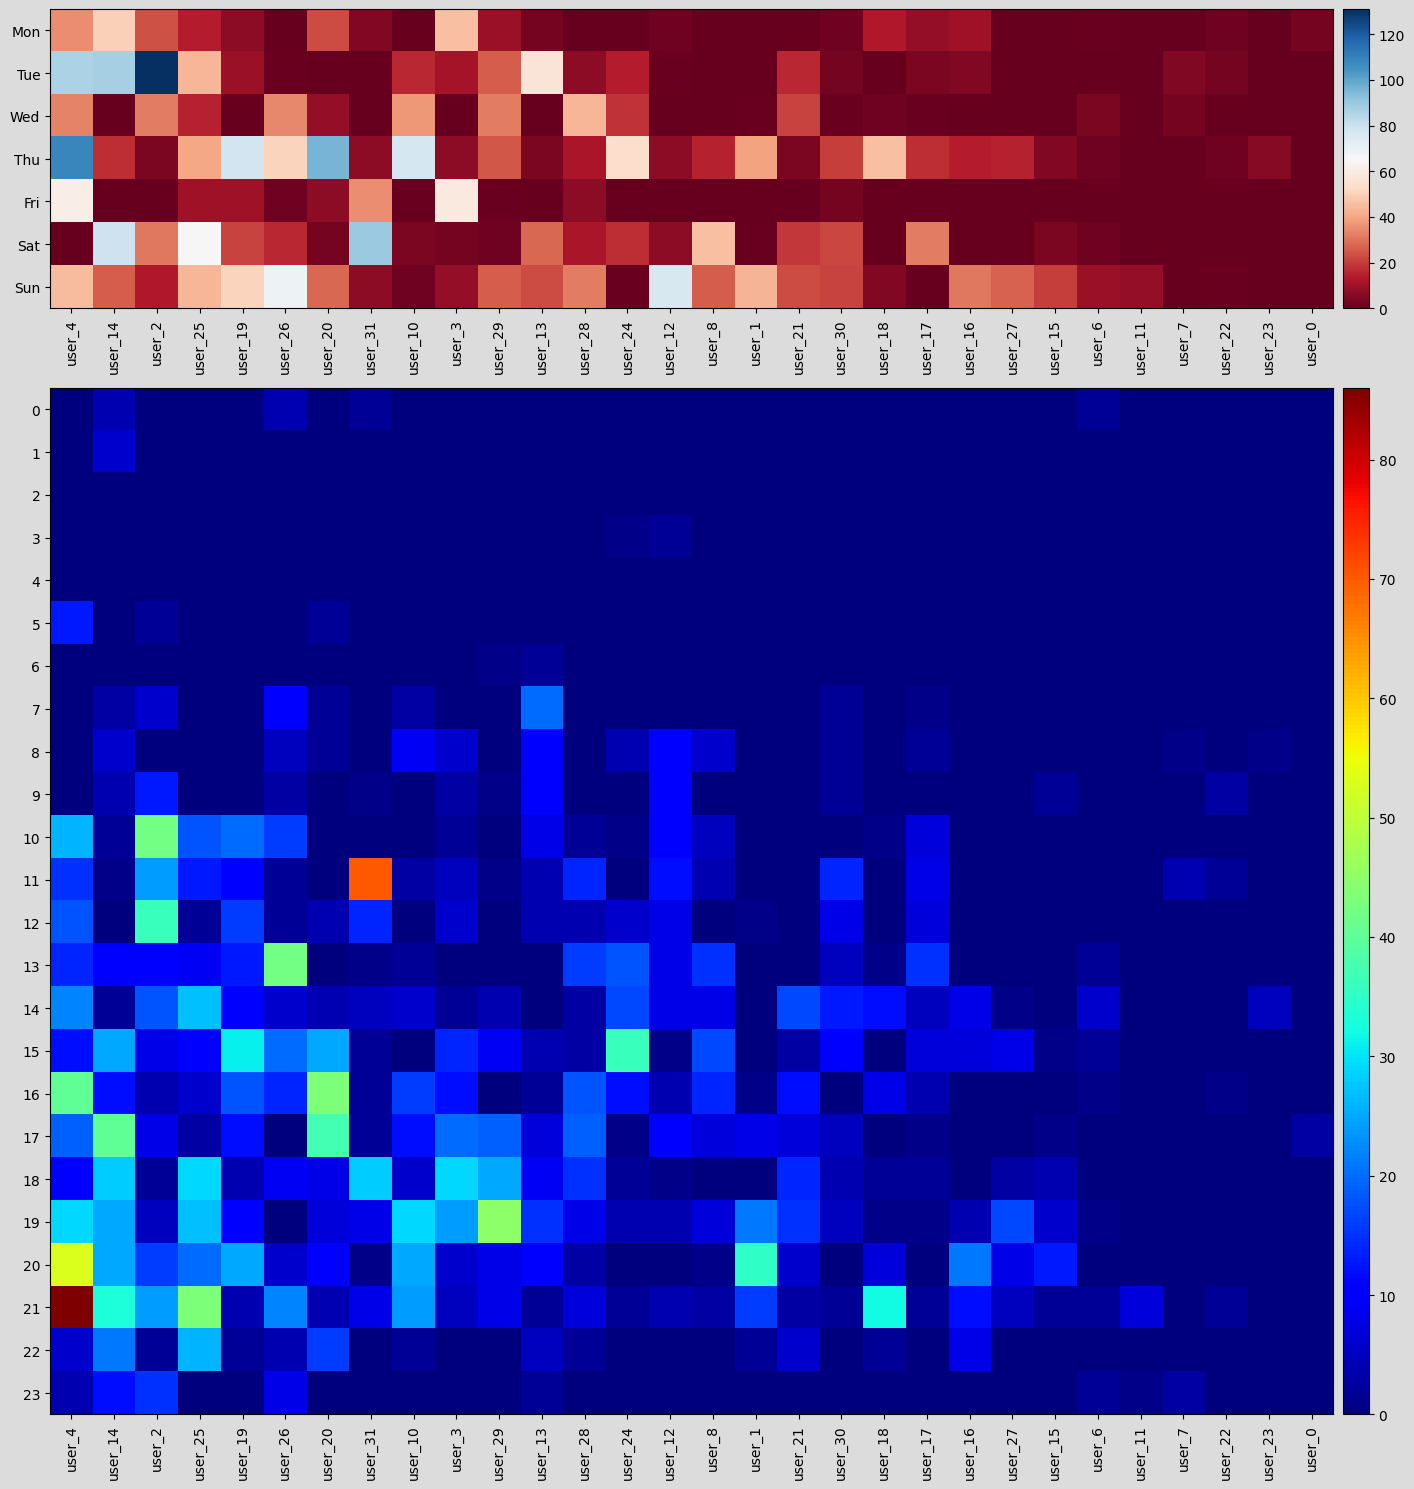

In [40]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 15), height_ratios=[7, 24])
fig.patch.set_facecolor("gainsboro")

plots_data = [
    (ax1, pvt_days.values, "RdBu", daysOrder),
    (ax2, pvt_hours.values, "jet", hoursOrder),
]

for ax, graph_values, palette, y_axis in plots_data:
    image = ax.imshow(graph_values, cmap=palette)

    ax.set_yticks(range(len(y_axis)))
    ax.set_yticklabels(y_axis)

    plot_divider = make_axes_locatable(ax)
    graph_legend = plot_divider.append_axes("right", size="2%", pad=0.1)
    fig.colorbar(image, cax=graph_legend)

for ax in (ax1, ax2):
    ax.set_xticks(range(len(userOrder)))
    ax.set_xticklabels(userOrder, rotation=90)

plt.tight_layout()
plt.show()

In [41]:
conn.close()

### «У какого пользователя больше всего коммитов во Вт?» Ответ: user_2.
### «У какого пользователя больше всего коммитов в Чт?» Ответ: user_4.
### «В какой день недели пользователи не любят много коммитить?» Ответ: Fri.
### «Какой пользователь и в который час сделал наибольшее число коммитов?» Ответ: user_4, 21.